In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge

In [12]:
# Función objetivo compleja
def true_function(x):
    return np.sin(2 * np.pi * x) + 0.3 * np.cos(5 * np.pi * x)

In [13]:
# Generar datos
np.random.seed(1)
X = np.sort(np.random.rand(100) * 2 - 1)
y_true = true_function(X)
y = y_true + np.random.normal(scale=0.3, size=X.shape)

In [14]:
# Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X.reshape(-1, 1), y, test_size=0.3, random_state=1)

In [15]:
# Modelos a evaluar
models = [
    ("Modelo 1: Polinomio grado 1 (lineal, simple)", make_pipeline(PolynomialFeatures(1), LinearRegression())),
    ("Modelo 2: Polinomio grado 4", make_pipeline(PolynomialFeatures(4), LinearRegression())),
    ("Modelo 3: Polinomio grado 12 (muy complejo)", make_pipeline(PolynomialFeatures(12), LinearRegression())),
    ("Modelo 4: Polinomio grado 8 + Ridge α=0.5", make_pipeline(PolynomialFeatures(8), Ridge(alpha=0.5))),
    ("Modelo 5: Polinomio grado 8 + Ridge α=100", make_pipeline(PolynomialFeatures(8), Ridge(alpha=100))),
]

In [16]:
# Puntos para graficar las curvas
X_plot = np.linspace(-1.2, 1.2, 500).reshape(-1, 1)

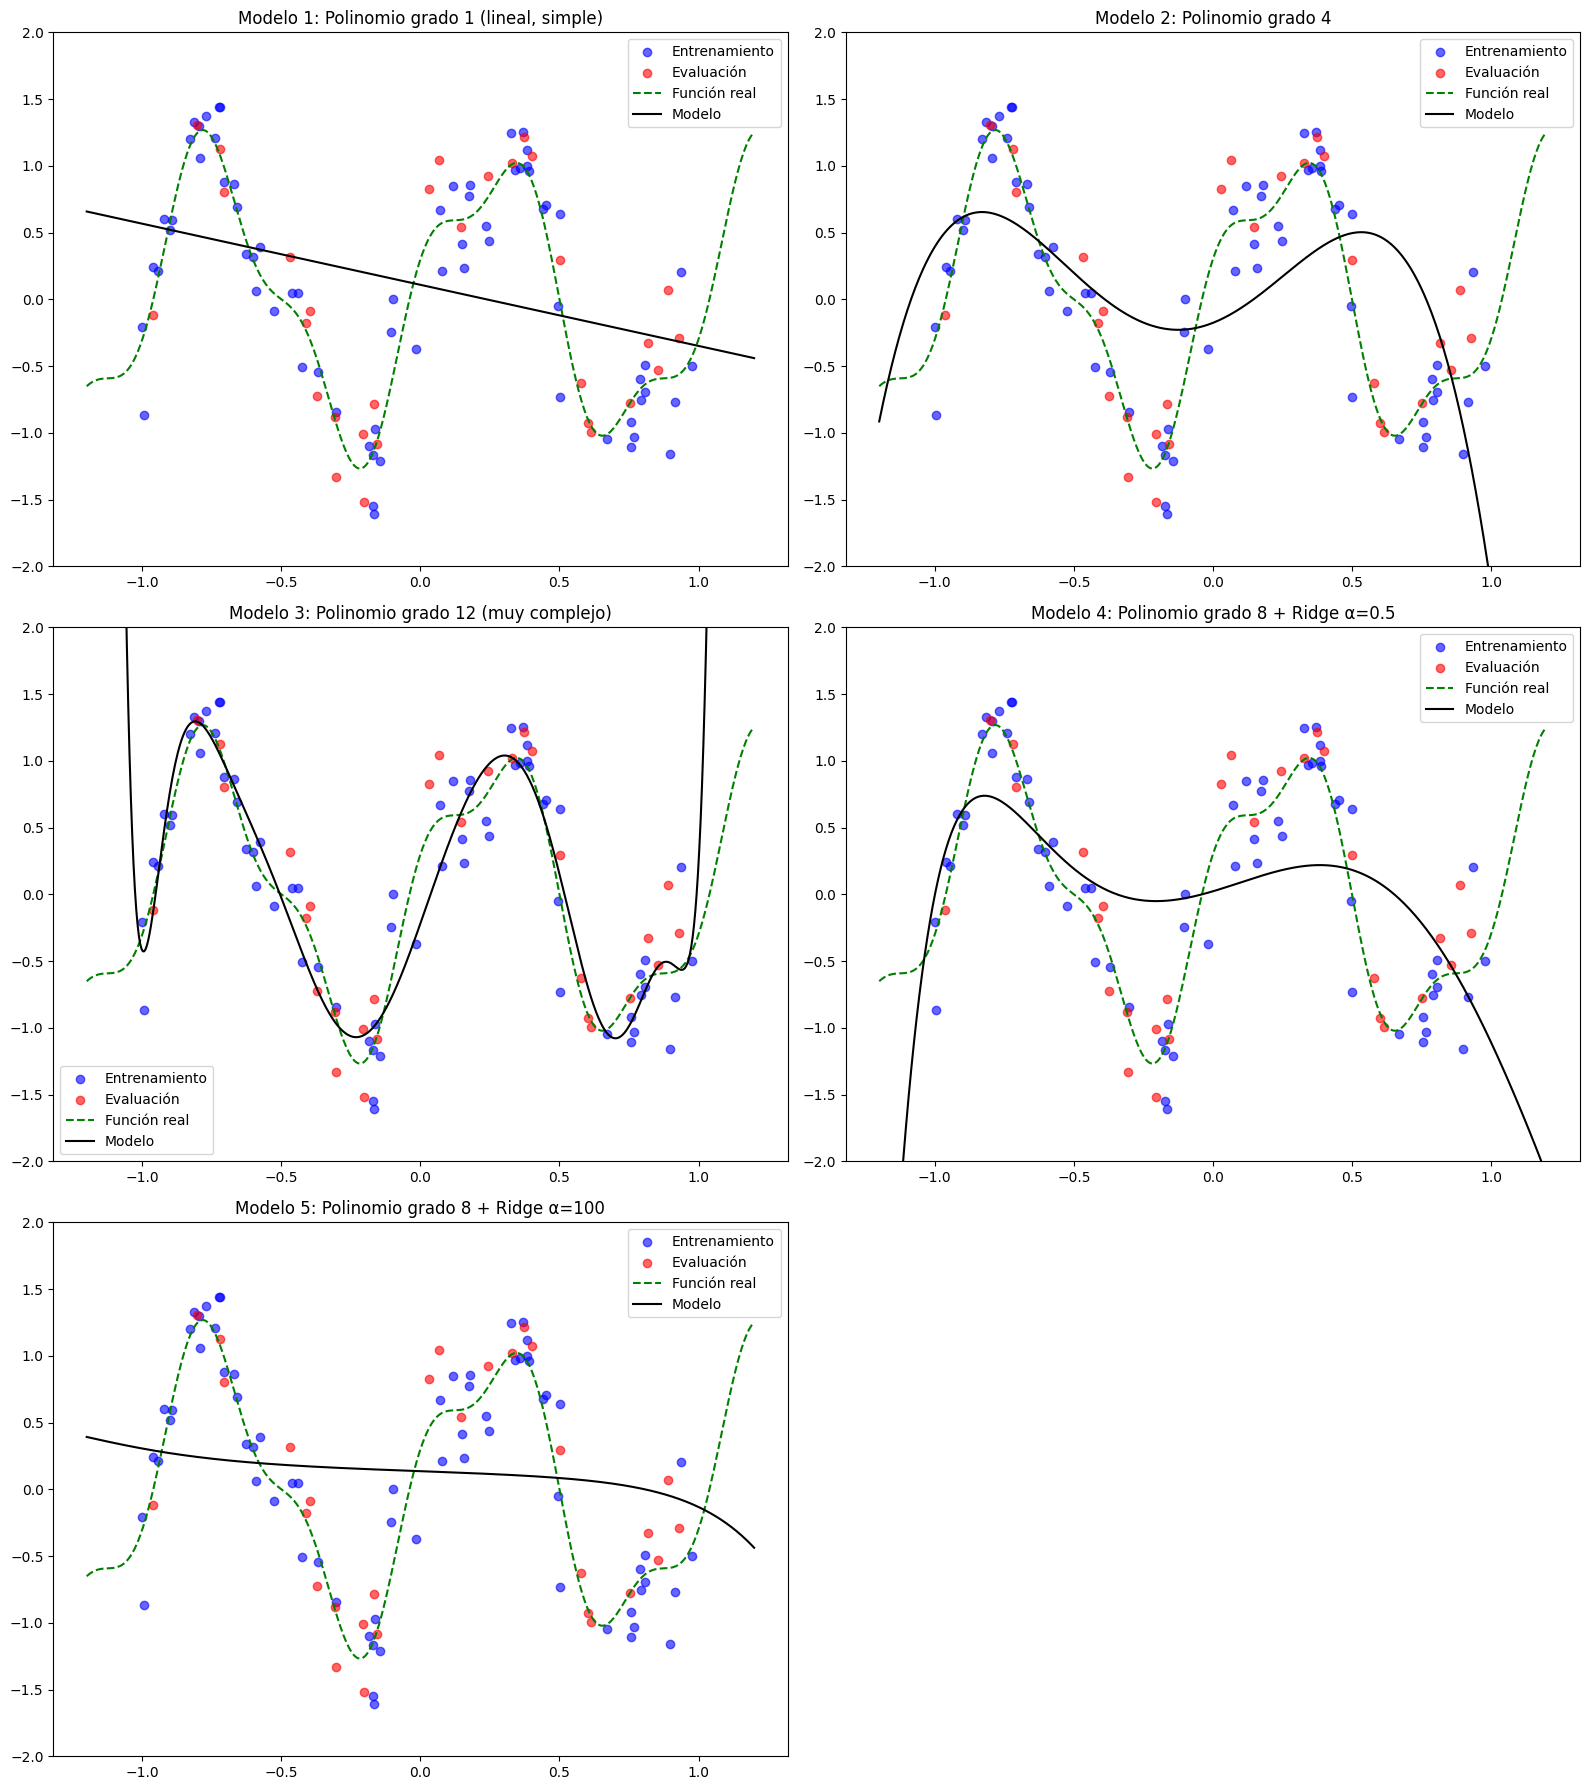

In [17]:
# Graficar resultados
fig, axs = plt.subplots(3, 2, figsize=(16, 18))
axs = axs.ravel()

for i, (title, model) in enumerate(models):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_plot)

    axs[i].scatter(X_train, y_train, color="blue", label="Entrenamiento", alpha=0.6)
    axs[i].scatter(X_test, y_test, color="red", label="Evaluación", alpha=0.6)
    axs[i].plot(X_plot, true_function(X_plot.ravel()), color="green", linestyle="dashed", label="Función real")
    axs[i].plot(X_plot, y_pred, color="black", label="Modelo")
    axs[i].set_title(title)
    axs[i].legend()
    axs[i].set_ylim(-2, 2)

# Ocultar el último eje si no se usa
axs[-1].axis('off')

plt.tight_layout()
plt.show()